In [121]:
%load_ext autoreload
%autoreload 2

from IPython.display import display
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
import torch
from torchvision.datasets import DatasetFolder, ImageFolder
import torchvision.utils as vutils
from torch.utils.data import DataLoader
from torchvision.transforms.functional import to_pil_image
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
import sklearn
from tqdm.notebook import tqdm
from PIL import Image

from compcats.datasets.fmri import nsd
from compcats.datasets.image import celebahq, afhqv2
from compcats.utils import model_utils, responsecomparison_utils as rc_utils
from compcats.models import resnet50_openaiclip
from compcats.encoder import encode

sys.path.append('../preprint')
from preprint import paths
from preprint import main_analysis as ma

from pil_image_transforms import orientation_filter, invert_image, scramble_image

MODELS_DIR = '../preprint/models'
RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)
PLOTS_DIR = 'plots'
os.makedirs(PLOTS_DIR, exist_ok=True)
STIMULI_DIR = 'stimuli'
os.makedirs(STIMULI_DIR, exist_ok=True)

SEED = 42

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
# Utils
# Get end to end torch encoding model
class EM(torch.nn.Module):
    def __init__(self, model, layer, mapping_coef, mapping_intercept):
        super(EM, self).__init__()
        self.model = model
        self.layer = layer
        
        # Convert sklearn mapping to torch.nn.Linear
        n_features = mapping_coef.shape[1]
        n_outputs = mapping_coef.shape[0]
        self.mapping_layer = torch.nn.Linear(n_features, n_outputs)
        
        # Set weights and bias from the sklearn model
        self.mapping_layer.weight.data = torch.FloatTensor(mapping_coef)
        self.mapping_layer.bias.data = torch.FloatTensor(mapping_intercept)
        
        # Get the layer module
        self.layer_module = dict([*self.model.model.named_modules()])[self.layer]
        
        # Register a forward hook to get the activations
        self.activations = None
        def hook(module, input, output):
            self.activations = output
        self.layer_module.register_forward_hook(hook)
    
    def forward(self, x):
        _ = self.model(x)
        # Get the activations
        x = self.activations
        x = x.reshape(x.shape[0], -1)
        # Apply the mapping directly with torch Linear layer
        x_mapped = self.mapping_layer(x)
        return x_mapped

In [39]:
subjects = [1, 2, 5, 7]
tthreshold_dict = {
    'rOFA': 3,
    'rFFA': 6
}
frois = ['rFFA', 'rOFA']

train_subset = 485
test_subset = 515

model = resnet50_openaiclip.get_model()
layer = 'layer4.1.conv3'
alpha = 0.1
seed = 42

# Layersweep

In [22]:
# for model_name in models
relevant_layers = model.relevant_layer_names
# Set relevant layers as last 25% of layers
n_layers = len(relevant_layers)
layers = relevant_layers[int(n_layers*0.75):]
print(f'Sweeping over the last {len(layers)} layers')
# for layer in layers
# Get model activations for train and test images
train_acts = model_utils.get_dataset_activations(
    MODELS_DIR, paths.NSD_DIR, model, layers, 'nsd', subset=train_subset
)
test_acts = model_utils.get_dataset_activations(
    MODELS_DIR, paths.NSD_DIR, model, layers, 'nsd', subset=test_subset
)
train_betas = {}
test_betas = {}
for froi in frois:
    train_betas[froi] = {}
    test_betas[froi] = {}
    for subject in subjects:
        # Get the voxel indices for the ROI
        tthreshold = tthreshold_dict[froi]
        train_betas[froi][subject], _ = nsd.get_betas(
            paths.NSD_DIR, subject, froi, tthreshold, subset=train_subset, voxels=True
        )
        test_betas[froi][subject], _ = nsd.get_betas(
            paths.NSD_DIR, subject, froi, tthreshold, subset=test_subset, voxels=True
        )

Sweeping over the last 37 layers


KeyboardInterrupt: 

In [53]:
mapper = Ridge()
alpha = 0.1
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

froi = 'rFFA'
subject = 2
layer = 'layer4.1.conv3'
# Fit ridge regression model
X_train = train_acts[layer].reshape(train_subset, -1).cpu().numpy()
Y_train = train_betas[froi][subject].cpu().numpy()
mapping_coef, mapping_intercept, train_corrs_mean, val_corrs_mean, \
    logs = encode.get_alpha_model(
        mapper, alpha, X_train,
        Y_train, kf
    )
print(f'Layer: {layer}, Mean train corr: {train_corrs_mean:.4f}, Mean val corr: {val_corrs_mean:.4f}')

/Users/adipani3/projects/catsel/comparing-category-selectivity/compcats/encoder/encode.py:51: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  test_metrics['pearsonr'], _ = scipy_stats.pearsonr(y_test, y_pred_test)
/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/sklearn/linear_model/_base.py:282: RuntimeWarning: invalid value encountered in add
  return X @ coef_.T + self.intercept_
/Users/adipani3/projects/catsel/comparing-category-selectivity/compcats/encoder/encode.py:51: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  test_metrics['pearsonr'], _ = scipy_stats.pearsonr(y_test, y_pred_test)
/Users/adipani3/projects/catsel/comparing-category-selectivity/compcats/encoder/encode.py:51: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  test_metrics['pearsonr'], _ = scipy_stats.pearsonr(y_test, y_pred_test)


Layer: layer4.1.conv3, Mean train corr: nan, Mean val corr: nan


/Users/adipani3/projects/catsel/comparing-category-selectivity/compcats/encoder/encode.py:51: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  test_metrics['pearsonr'], _ = scipy_stats.pearsonr(y_test, y_pred_test)


In [32]:
X_train

array([[-0.05693796, -0.05572803, -0.07221964, ...,  0.08680838,
         0.09722608,  0.05925836],
       [-0.03144746, -0.06053122, -0.06347987, ...,  0.08582387,
         0.09902651,  0.09058142],
       [ 0.00204463, -0.05729553, -0.03269941, ...,  0.13048486,
         0.10346551,  0.05421779],
       ...,
       [ 0.00203698, -0.07967629, -0.11330995, ...,  0.01517802,
         0.02395243,  0.04388992],
       [ 0.00479562,  0.04998514,  0.01934973, ...,  0.08130316,
         0.05851239,  0.07002228],
       [ 0.01906925, -0.0706653 , -0.10274909, ...,  0.11485131,
         0.14255022,  0.05206124]], dtype=float32)

In [ ]:
for froi in frois:
    for subject in subjects:
        print(f'Fitting mappings for {froi}, subject {subject}')
        # Fit ridge regression model
        mapping_coef, mapping_intercept = rc_utils.fit_ridge_regression(
            train_acts, train_betas[froi][subject], alpha=alpha, seed=seed
        )
        # Save the mapping coefficients and intercepts
        np.savez_compressed(
            os.path.join(RESULTS_DIR, f'mapping_{model.name}_{layer}_{froi}_subj{subject}.npz'),
            coef=mapping_coef,
            intercept=mapping_intercept
        )
        # Get test predictions
        test_pred = rc_utils.get_ridge_regression_predictions(
            test_acts, mapping_coef, mapping_intercept
        )
        # Save the test predictions
        np.savez_compressed(
            os.path.join(RESULTS_DIR, f'test_pred_{model.name}_{layer}_{froi}_subj{subject}.npz'),
            test_pred=test_pred
        )
        
        # Get the end to end model
        emodel = EM(model, layer, mapping_coef, mapping_intercept)
        emodel.eval()
        # Save the end to end model
        torch.save(
            emodel.state_dict(),
            os.path.join(RESULTS_DIR, f'end_to_end_model_{model.name}_{layer}_{froi}_subj{subject}.pth')
        )

# Training

In [47]:
resultd_save_dir = f'{RESULTS_DIR}/EMs_nolayersweep/'
os.makedirs(resultd_save_dir, exist_ok=True)
results_file_name = f'EM_nolayersweep_{model.name}_{layer}_ridge_alpha{alpha}.npz'

all_results = {}

if os.path.exists(os.path.join(RESULTS_DIR, results_file_name)):
    all_results = np.load(
        os.path.join(RESULTS_DIR, results_file_name),
        allow_pickle=True
    )
    all_results = {
        key: (all_results[key].item() if isinstance(all_results[key], np.ndarray) and all_results[key].dtype == object else all_results[key])
        for key in all_results.files
    }
else:
    for froi in frois:
        all_results[froi] = {}
        fmri_tthreshold = tthreshold_dict[froi]
        for subject in subjects:
            # Get subject data
            Y_trainval, _ = nsd.get_betas(
                paths.NSD_DIR, subject, froi, fmri_tthreshold, subset=train_subset, voxels=True
            )
            Y_trainval = Y_trainval.cpu().numpy()
            Y_test, _ = nsd.get_betas(
                paths.NSD_DIR, subject, froi, fmri_tthreshold, subset=test_subset, voxels=True
            )
            # Get activations for the model and layer
            X_trainval_fulllayer = model_utils.get_dataset_activations(
                MODELS_DIR, paths.NSD_DIR, model, layer, 'nsd', subset=train_subset
            )
            X_test_fulllayer = model_utils.get_dataset_activations(
                MODELS_DIR, paths.NSD_DIR, model, layer,
                'nsd', subset=test_subset
            )
            # Layer
            X_trainval = X_trainval_fulllayer.reshape(X_trainval_fulllayer.shape[0], -1).cpu().numpy()
            X_test = X_test_fulllayer.reshape(X_test_fulllayer.shape[0], -1).cpu().numpy()
            # Map
            print(f'FROI: {froi}, Model: {model.name}, Subject: {subject}, tthreshold: {fmri_tthreshold}, mapper: Ridge')
            mapping = mapping = sklearn.linear_model.Ridge(alpha=alpha, random_state=seed)
            # Fit the mapping
            mapping.fit(X_trainval, Y_trainval)
            # Get train performance
            Y_trainval = torch.FloatTensor(Y_trainval)
            y_pred_trainval = torch.FloatTensor(mapping.predict(X_trainval))
            train_pearsonr = rc_utils.pearsonr(Y_trainval.mean(axis=-1), y_pred_trainval.mean(axis=-1))
            train_rdmr = rc_utils.rdmr(Y_trainval, y_pred_trainval)
            print(f'Train Pearsonr: {train_pearsonr:.4f}, Train RDMR: {train_rdmr:.4f}')
            # Get test performance
            y_pred_test = torch.FloatTensor(mapping.predict(X_test))
            test_pearsonr = rc_utils.pearsonr(Y_test.mean(axis=-1), y_pred_test.mean(axis=-1))
            test_rdmr = rc_utils.rdmr(Y_test, y_pred_test)
            print(f'Test Pearsonr: {test_pearsonr:.4f}, Test RDMR: {test_rdmr:.4f}')

            # Save results
            results = {
                'froi': froi,
                'model': model.name,
                'layer': layer,
                'subject': subject,
                'tthreshold': tthreshold_dict[froi],
                'mapper': 'Ridge',
                'alpha': alpha,
                'train_pearsonr': train_pearsonr,
                'train_rdmr': train_rdmr,
                'test_pearsonr': test_pearsonr,
                'test_rdmr': test_rdmr,
                'coef_': mapping.coef_,
                'intercept_': mapping.intercept_,
            }
            all_results[froi][subject] = results
    np.savez(
        os.path.join(RESULTS_DIR, results_file_name),
        **all_results
    )

In [49]:
all_results['rFFA'][1]

{'froi': 'rFFA',
 'model': 'resnet50openaiclip',
 'layer': 'layer4.1.conv3',
 'subject': 1,
 'tthreshold': 6,
 'mapper': 'Ridge',
 'alpha': 0.1,
 'train_pearsonr': 1.0,
 'train_rdmr': 0.9999998610425697,
 'test_pearsonr': 0.7711638808250427,
 'test_rdmr': 0.5451974206816044,
 'coef_': array([[-9.8639273e-04,  6.7967095e-04, -1.8856570e-04, ...,
          1.1288965e-03,  3.6872115e-03, -1.3505716e-03],
        [-5.9132546e-04,  1.5011693e-04, -8.8071707e-04, ...,
          2.2863704e-03,  3.0149354e-03,  6.1203127e-06],
        [-6.1272399e-04,  7.8395440e-04, -1.1443275e-03, ...,
          2.5982421e-03, -3.1560229e-03,  2.8912403e-04],
        ...,
        [ 1.8289490e-03,  3.9435248e-03, -1.4965644e-04, ...,
         -1.6286541e-03, -2.7478603e-03,  9.9776546e-04],
        [-8.0542749e-04,  1.1542516e-03,  9.2340528e-04, ...,
          1.5973176e-03, -6.5709837e-04, -3.1258044e-04],
        [-2.1471994e-04,  3.4727147e-03,  5.9603557e-05, ...,
         -1.5453004e-03, -2.5076047e-03,

In [50]:
subject = 1
froi = 'rFFA'

em_sbj_froi = EM(model, layer, all_results[froi][subject]['coef_'], all_results[froi][subject]['intercept_'])

# Predictions on experimental stimuli

In [8]:
from torch.utils.data import Dataset, DataLoader

class ImageDataset(Dataset):
    """Dataset for a single folder of images, without labels."""
    def __init__(self, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform
        # List all files and ensure they are images (e.g., .bmp, .png, .jpg)
        self.img_names = sorted([f for f in os.listdir(img_dir) if f.lower().endswith(('.bmp', '.png', '.jpg', '.jpeg'))])

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_names[idx])
        image = Image.open(img_path).convert("RGB")
        
        # We'll return the original filename along with the image.
        # This is very useful for inference tasks.
        filename = self.img_names[idx]

        if self.transform:
            image = self.transform(image)
            
        return image, filename

In [9]:
STIMULI_DIR = f'stimuli_MD'

dataset = ImageDataset(STIMULI_DIR, transform=model.transforms)

data_loader = DataLoader(
        dataset=dataset,
        batch_size=512,
        shuffle=False,      # IMPORTANT: Set to False for sequential processing
        num_workers=16
    )

In [30]:
predictions_dir = f'{RESULTS_DIR}/predictions/'
os.makedirs(predictions_dir, exist_ok=True)

for froi in frois:
    for subject in subjects:
        mapping = all_results[froi][subject]
        mapping_coef = mapping['coef_']
        mapping_intercept = mapping['intercept_']
        em = EM(model, layer, mapping_coef, mapping_intercept)
        em = em.cuda()
        em.eval()
        with torch.no_grad():
            assert len(data_loader) == 1, "DataLoader should have only one batch for all images."
            for batch in data_loader:
                images, filenames = batch
                images = images.cuda()
                preds = em(images)
        # Convert filenames and preds to a csv with first column as filenames and rest as preds
        preds = preds.cpu().numpy()
        df = pd.DataFrame(preds)
        df.insert(0, 'filename', filenames)
        output_csv = f'{predictions_dir}/predictions_{froi}_t{tthreshold_dict[froi]}_{subject}.csv'
        df.to_csv(output_csv, index=False)
        print(f'Saved predictions to {output_csv}')

torch.Size([420, 123])
torch.Size([420, 177])
torch.Size([420, 194])
torch.Size([420, 56])
torch.Size([420, 64])
torch.Size([420, 76])
torch.Size([420, 188])
torch.Size([420, 96])


# New stimuli on CelebA-HQ

In [ ]:
celebahq_img_paths = glob(f'{paths.CELEBAHQ_VAL_DIR}/*/*.jpg')
orentation_angles = list(range(0, 181, 15))
# Create folders for inverted and scrambled images, and orientation filtered images (this one will have subfolders for each angle)
inverted_dir = f'{STIMULI_DIR}/inverted'
scrambled_dir = f'{STIMULI_DIR}/scrambled'
os.makedirs(inverted_dir, exist_ok=True)
os.makedirs(scrambled_dir, exist_ok=True)
orientation_dir = f'{STIMULI_DIR}/orientation_filtered'
os.makedirs(orientation_dir, exist_ok=True)
for angle in orentation_angles:
    os.makedirs(f'{orientation_dir}/{angle}', exist_ok=True)

for img_path in tqdm(celebahq_img_paths):
    img_name = os.path.basename(img_path)
    img = Image.open(img_path).convert('RGB')
    # Inverted
    img_inverted = invert_image(img)
    img_inverted.save(f'{inverted_dir}/{img_name}')
    # Scrambled
    img_scrambled = scramble_image(img)
    img_scrambled.save(f'{scrambled_dir}/{img_name}')
    # Orientation filtered
    for angle in orentation_angles:
        img_orient = orientation_filter(img, angle_deg=angle)
        img_orient.save(f'{orientation_dir}/{angle}/{img_name}')

KeyboardInterrupt: 

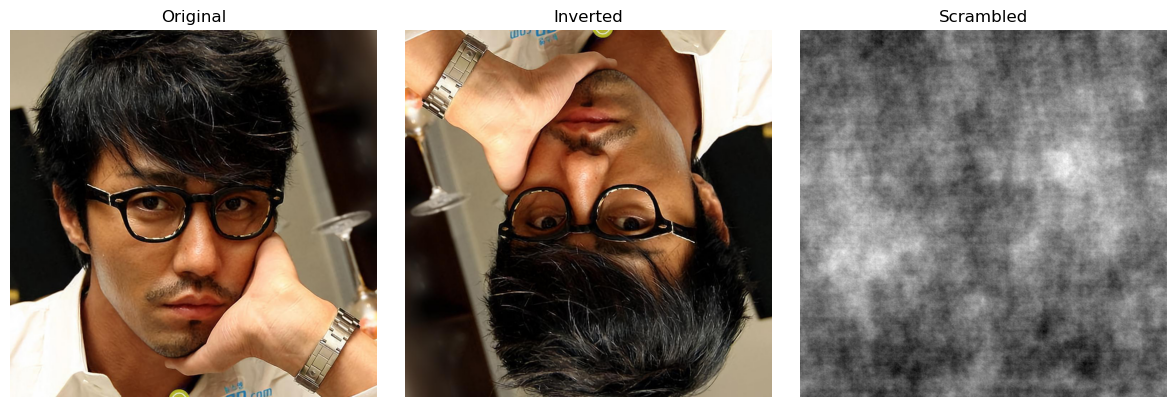

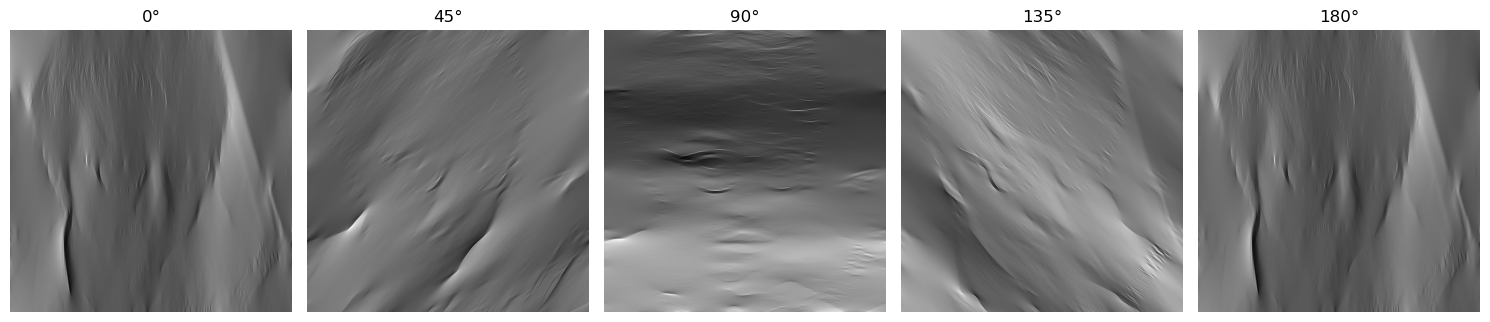

In [124]:
example_idx = 0
img0 = Image.open(celebahq_img_paths[example_idx]).convert('RGB')
img0_inverted = Image.open(f'{inverted_dir}/{os.path.basename(celebahq_img_paths[example_idx])}').convert('RGB')
img0_scrambled = Image.open(f'{scrambled_dir}/{os.path.basename(celebahq_img_paths[example_idx])}').convert('RGB')
# Show original, inverted and scrambled in one figure
plt.figure(figsize=(12, 4))
imgs = [(img0, 'Original'), (img0_inverted, 'Inverted'), (img0_scrambled, 'Scrambled')]
for i, (im, title) in enumerate(imgs, 1):
    ax = plt.subplot(1, 3, i)
    cmap = 'gray' if im.mode == 'L' else None
    ax.imshow(im, cmap=cmap)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Show orientation-filtered images from 0 to 180 every 30 degrees
angles = list(range(0, 181, 45))
n = len(angles)
plt.figure(figsize=(3 * n, 4))
for i, ang in enumerate(angles, 1):
    imf = Image.open(f'{orientation_dir}/{ang}/{os.path.basename(celebahq_img_paths[example_idx])}').convert('RGB')
    ax = plt.subplot(1, n, i)
    cmap = 'gray' if imf.mode == 'L' else None
    ax.imshow(imf, cmap=cmap)
    ax.set_title(f'{ang}°')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [109]:
import os
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

class ImageFolderNoLabels(Dataset):
    def __init__(self, folder_path, transform=None):
        self.image_paths = [
            os.path.join(folder_path, f)
            for f in os.listdir(folder_path)
            if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff'))
        ]
        if not self.image_paths:
            raise FileNotFoundError(f"No image files found in {folder_path}")
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img

In [123]:
# Loop over all new stimuli folders, collect predictions for all conditions into one CSV per subject/froi
new_stimuli_base_dir = STIMULI_DIR
new_stimuli_folders = [
    'inverted',
    'scrambled'
] + [f'orientation_filtered/{angle}' for angle in orentation_angles]

predictions_dir = f'{RESULTS_DIR}/predictions_new_stimuli/'
os.makedirs(predictions_dir, exist_ok=True)

for froi in frois:
    for subject in subjects:
        mapping = all_results[froi][subject]
        mapping_coef = mapping['coef_']
        mapping_intercept = mapping['intercept_']
        em = EM(model, layer, mapping_coef, mapping_intercept)

        device = torch.device('mps') if torch.backends.mps.is_available() else (
                 torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu'))
        em = em.to(device)
        em.eval()

        dfs = []  # collect dataframes for all conditions

        for stim_folder in new_stimuli_folders:
            stim_dir = os.path.join(new_stimuli_base_dir, stim_folder)
            if not os.path.isdir(stim_dir):
                print(f"Skipping missing folder: {stim_dir}")
                continue

            try:
                dataset = ImageFolderNoLabels(stim_dir, transform=model.transforms)
            except FileNotFoundError:
                print(f"Skipping empty folder: {stim_dir}")
                continue

            n = min(100, len(dataset))
            if n == 0:
                print(f"Skipping empty folder: {stim_dir}")
                continue

            subset_indices = list(range(n))
            selected_paths = [dataset.image_paths[i] for i in subset_indices]
            selected_filenames = [os.path.basename(p) for p in selected_paths]

            subset_dataset = torch.utils.data.Subset(dataset, subset_indices)
            data_loader = DataLoader(
                dataset=subset_dataset,
                batch_size=32,
                shuffle=False,
                num_workers=0
            )

            all_preds = []
            with torch.no_grad():
                for batch in data_loader:
                    images = batch  # ImageFolderNoLabels returns image tensor only
                    images = images.to(device)
                    preds = em(images)
                    all_preds.append(preds.cpu().numpy())

            if len(all_preds) == 0:
                print(f"No predictions for {stim_folder} (empty dataset).")
                continue

            all_preds = np.vstack(all_preds)  # shape (n, n_voxels)
            n_samples, n_voxels = all_preds.shape

            voxel_cols = [f'voxel_{i}' for i in range(n_voxels)]
            df_voxels = pd.DataFrame(all_preds, columns=voxel_cols)

            meta = {
                'subject': [subject] * n_samples,
                'froi': [froi] * n_samples,
                'condition': [stim_folder] * n_samples,
                'image_index': list(range(n_samples)),
                'filename': selected_filenames
            }
            df_meta = pd.DataFrame(meta)

            df = pd.concat([df_meta, df_voxels], axis=1)
            dfs.append(df)

        if len(dfs) == 0:
            print(f"No conditions processed for {froi} subject {subject}, skipping CSV save.")
            continue

        # Combine all conditions into a single dataframe and save once per froi/subject
        df_all = pd.concat(dfs, axis=0, ignore_index=True)
        output_csv = os.path.join(predictions_dir, f'predictions_allconditions_{froi}_t{tthreshold_dict[froi]}_{subject}.csv')
        df_all.to_csv(output_csv, index=False)
        print(f'Saved combined predictions to {output_csv}')

Saved combined predictions to results/predictions_new_stimuli/predictions_allconditions_rFFA_t6_1.csv
Saved combined predictions to results/predictions_new_stimuli/predictions_allconditions_rFFA_t6_2.csv
Saved combined predictions to results/predictions_new_stimuli/predictions_allconditions_rFFA_t6_5.csv
Saved combined predictions to results/predictions_new_stimuli/predictions_allconditions_rFFA_t6_7.csv
Saved combined predictions to results/predictions_new_stimuli/predictions_allconditions_rOFA_t3_1.csv
Saved combined predictions to results/predictions_new_stimuli/predictions_allconditions_rOFA_t3_2.csv
Saved combined predictions to results/predictions_new_stimuli/predictions_allconditions_rOFA_t3_5.csv
Saved combined predictions to results/predictions_new_stimuli/predictions_allconditions_rOFA_t3_7.csv


In [ ]:
# Average orientation tuning across subjects and plot one figure per froi
predictions_dir = f'{RESULTS_DIR}/predictions_new_stimuli/'
plot_dir = f'{PLOTS_DIR}/orientation_dependence_mean_across_subjects/'
os.makedirs(plot_dir, exist_ok=True)

for froi in frois:
    subj_series = []
    subj_ids = []
    for subject in subjects:
        input_csv = os.path.join(predictions_dir, f'predictions_allconditions_{froi}_t{tthreshold_dict[froi]}_{subject}.csv')
        if not os.path.exists(input_csv):
            print(f"Missing {input_csv}, skipping subject {subject} for {froi}")
            continue
        df = pd.read_csv(input_csv)
        df_orient = df[df['condition'].str.startswith('orientation_filtered')].copy()
        if df_orient.empty:
            print(f"No orientation data for {froi} subject {subject}, skipping")
            continue
        df_orient['angle'] = df_orient['condition'].str.split('/').str[1].astype(int)
        voxel_cols = [c for c in df_orient.columns if c.startswith('voxel_')]
        df_orient['voxel_mean'] = df_orient[voxel_cols].mean(axis=1)
        mean_resp = df_orient.groupby('angle')['voxel_mean'].mean()
        # Reindex to full set of angles to ensure consistent ordering (use orentation_angles defined earlier)
        mean_resp = mean_resp.reindex(orentation_angles)
        subj_series.append(mean_resp)
        subj_ids.append(subject)

    if len(subj_series) == 0:
        print(f"No subjects with orientation data for {froi}, skipping plot.")
        continue

    df_subj = pd.concat(subj_series, axis=1)
    df_subj.columns = [f'subj_{s}' for s in subj_ids]

    mean_across = df_subj.mean(axis=1)
    sem_across = df_subj.std(axis=1) / np.sqrt(df_subj.shape[1])

    plt.figure(figsize=(8,6))
    plt.errorbar(orentation_angles, mean_across.values, yerr=sem_across.values, marker='o', capsize=3)
    plt.title(f'Orientation Dependence (mean across subjects) - {froi}')
    plt.xlabel('Orientation Angle (degrees)')
    plt.ylabel('Mean Voxel Response (±SEM)')
    plt.xticks(orentation_angles, rotation=45)
    # plt.grid(True)
    plt.tight_layout()
    plot_path = os.path.join(plot_dir, f'orientation_dependence_mean_{froi}.png')
    plt.savefig(plot_path)
    plt.close()
    print(f"Saved mean-across-subjects plot for {froi} to {plot_path}")

Saved mean-across-subjects plot for rFFA to plots/orientation_dependence_mean_across_subjects/orientation_dependence_mean_rFFA.png
Saved mean-across-subjects plot for rOFA to plots/orientation_dependence_mean_across_subjects/orientation_dependence_mean_rOFA.png


: 

In [107]:
new_stimuli_folders

['inverted',
 'scrambled',
 'orientation_filtered/0',
 'orientation_filtered/15',
 'orientation_filtered/30',
 'orientation_filtered/45',
 'orientation_filtered/60',
 'orientation_filtered/75',
 'orientation_filtered/90',
 'orientation_filtered/105',
 'orientation_filtered/120',
 'orientation_filtered/135',
 'orientation_filtered/150',
 'orientation_filtered/165',
 'orientation_filtered/180']

In [66]:
celebahq_dataset = celebahq.get_val_dataset(paths.CELEBAHQ_VAL_DIR, model.transforms)

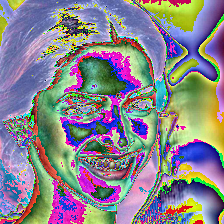

In [67]:
# Show first image and its label
# Show the PIL image
display(to_pil_image(celebahq_dataset[0][0]))